In [ ]:
import pandas as pd
import torch
import tqdm
import numpy as np
import scipy.special as scipy_special

import matplotlib.pyplot as plt

from agfn.gym import MAG_HITL, LogReward
from agfn.policies import ForwardPolicyHITL, BackwardPolicyHITL

from agfn.modules.gflownet import GFlowNet

from agfn.commons import is_mag

torch.manual_seed(42)

In [2]:
device = "cpu"
assert device == "cpu", "Currently, only CPU is supported"

## Load data

In [3]:
data_path = "data/chain4_dat01.csv"
data_path = "data/collfork_dat01.csv"
data = pd.read_csv(data_path)
data = torch.tensor(data.values, dtype=torch.get_default_dtype(), device=device)

num_nodes = data.shape[1]

In [4]:
hidden_dim = 128
num_layers = 2

pf = ForwardPolicyHITL(num_nodes, hidden_dim, num_layers, device=device)
pb = BackwardPolicyHITL(device=device)

gfn = GFlowNet(pf, pb, criterion="cb", device=device)

In [5]:
log_reward = LogReward(data, device=device)
# from agfn.gym import LogRewardSlightlyComplex
# log_reward = LogRewardSlightlyComplex(num_nodes, device=device)

initial_state = MAG_HITL(num_nodes, 256, log_reward)
if isinstance(log_reward, LogReward):
    log_reward.warmup(gfn, initial_state=initial_state, num_batches=8)

In [6]:
state = gfn.sample(
    initial_state
)

p, s = state.parents_and_spouses

is_graph_mag, th = is_mag(p, s, return_th=True)
assert is_graph_mag.all(), (th.mean(), th)

## Train an AGFN

In [7]:
gfn.train()
opt = torch.optim.Adam([
    {"params": gfn.pf.parameters(), "lr": 1e-3},
    {"params": gfn.log_z, "lr": 1e-1},
])

num_epochs = int(125)

sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=num_epochs)

log_z_values = []

pbar = tqdm.tqdm(range(num_epochs))

for _ in pbar:
    initial_state = MAG_HITL(num_nodes, 256, log_reward)
    opt.zero_grad()
    loss = gfn(initial_state)
    loss.backward()
    opt.step()
    sch.step()

    log_z_values.append(gfn.log_z.detach().cpu().item())
    
    pbar.set_postfix(loss=loss.item())

100%|██████████| 125/125 [00:04<00:00, 26.88it/s, loss=0.355]


In [8]:
gfn.eval()
# Sample a lot of graphs and compute their relative frequencies
graphs = []
log_rewards = []

for _ in tqdm.trange(int(1e2)):
    initial_state = MAG_HITL(num_nodes, 256, log_reward)
    state = gfn.sample(initial_state)
    graphs.append(state.adjacency_matrix.cpu().numpy())
    log_rewards.append(state.log_reward().cpu().numpy())

graphs = np.concatenate(graphs, axis=0)
log_rewards = np.concatenate(log_rewards, axis=0)

100%|██████████| 100/100 [00:04<00:00, 23.11it/s]


In [9]:
_, indices, counts = np.unique(graphs, axis=0, return_counts=True, return_index=True)
empirical_freq = np.log(counts) - np.log(counts.sum())
expected_freq = log_rewards[indices] - scipy_special.logsumexp(log_rewards[indices])

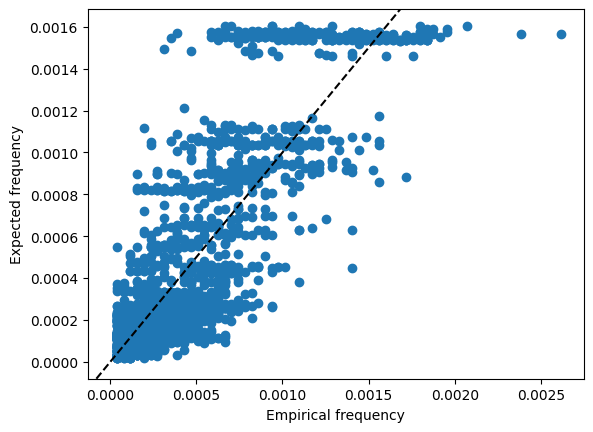

In [10]:
plt.scatter(
    np.exp(empirical_freq), np.exp(expected_freq)
)

plt.axline((0, 0), slope=1, color="black", linestyle="--")
plt.xlabel("Empirical frequency")
plt.ylabel("Expected frequency")
plt.show()

## Posterior update from human feedback

In [11]:
import networkx as nx

from agfn.commons import EdgeType
from agfn.hitl import (
    get_response_from_oracle, 
    find_next_query,
    posterior_from_responses, 
    log_score_from_responses,
    ElicitationStrategy,
)

In [12]:
def feedback_from_oracle(query: int) -> EdgeType:
    global data_path
    match data_path:
        case "data/chain4_dat01.csv":
            # a -> b -> c -> d
            adj = torch.zeros(num_nodes, num_nodes)
            adj[0, 1] = 1
            adj[1, 2] = 1
            adj[2, 3] = 1
        case "data/collfork_dat01.csv":
            # vars = [W, X, Y, Z]
            # X -> Z <-> Y <- W
            # X <-> W -> Z
            adj = torch.zeros(num_nodes, num_nodes)
            # W (0), X (1), Y (2), Z (3)
            # X -> Z: 1 -> 3
            adj[1, 3] = 1
            # Z <-> Y: 3 <-> 2
            adj[3, 2] = 1
            adj[2, 3] = 1
            # Y <- W: 2 <- 0
            adj[0, 2] = 1
            # X <-> W: 1 <-> 0
            adj[1, 0] = 1
            adj[0, 1] = 1
            # W -> Z: 0 -> 3
            adj[0, 3] = 1
    return get_response_from_oracle(query, adj)

In [ ]:
initial_state = MAG_HITL(num_nodes, 256, log_reward)

num_feedbacks = initial_state.max_num_edges

queries = []
responses = []

prior_pi = 1 - 1e-3
pis = []

for _ in tqdm.trange(num_feedbacks):
    query = find_next_query(ElicitationStrategy.ENTROPY, queries=queries, responses=responses, pis=pis, num_nodes=num_nodes)
    response = feedback_from_oracle(query)
    queries.append(query)
    responses.append(response.value)

    # We assume a constant confidence factor for these experiments.
    # In practice, the expert would be able to provide a subjective and variable confidence factor
    # for each query.
    pis.append(prior_pi)

    gfn.set_posterior(posterior_from_responses(responses, queries, initial_state.max_num_edges, pis))

100%|██████████| 6/6 [00:00<00:00, 2166.85it/s]


In [16]:
# Sample from the posterior
samples = gfn.sample(initial_state)

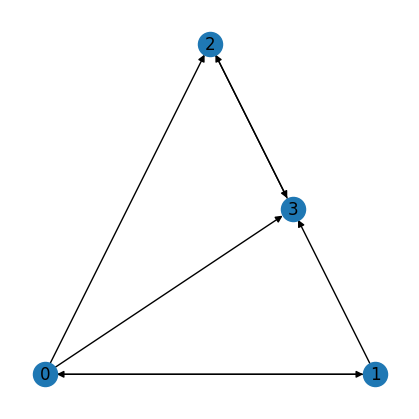

In [17]:
initial_scores = samples.log_reward()
avg_pi = np.mean(pis)
scores = log_score_from_responses(samples, queries, responses, log_reward_coef=1/(avg_pi * num_feedbacks), pis=pis)
_, largest_reward_samples = torch.topk(scores, k=100)

adjacency_matrices = samples.adjacency_matrix.cpu().numpy()
adjacency_matrices = np.unique(adjacency_matrices[largest_reward_samples], axis=0)

for i in range(len(adjacency_matrices)):
    g = nx.from_numpy_array(adjacency_matrices[i], create_using=nx.MultiDiGraph)
    layout = nx.planar_layout(g)
    plt.figure(figsize=(4, 4))
    nx.draw(g, pos=layout, with_labels=True)
    plt.show()